# 09 — Escala: o gráfico log-log de L1 e L2, e um teste para o expoente α

## O que este notebook mostra

Na Aula 4 (slides 22–26 e 43–44) uma lei de escala aparece como uma reta num gráfico **log-log**: se

$$Y = A\,X^{\beta}$$

então $\log Y = \log A + \beta\,\log X$, e o expoente $\beta$ é a inclinação da reta. Este notebook desenha esses gráficos para o nosso trabalho:

- **L1 (escala entre cidades):** número de pronto-atendimentos (PAs) de cada capital contra a população da capital. Slide 23 da Aula 4: $\beta<1$ é o caso "eficiência/otimização", $\beta=1$ é proporcional, $\beta>1$ é superlinear.
- **L2 (densidade dentro das cidades):** densidade de PAs contra densidade de moradores, onde cada ponto é uma *área de atendimento* (os setores do IBGE cujo PA mais próximo pela rua é o mesmo). É a conta dos slides 43–44 (Gastner & Newman; Um et al.), em que a referência ótima é $\alpha = 2/3$.

Depois fazemos um **teste de embaralhamento** para saber o quanto do $\alpha$ vem da própria matemática da conta e o quanto vem de onde os PAs realmente estão.

Tudo usa as tabelas já geradas nos notebooks 02 e 05 (SUS é o recorte principal).

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/"PLANO.md").exists())
sys.path.insert(0, str(RAIZ/"scripts"))
import estilo
estilo.aplicar()
ANA = RAIZ/"dados/processados/analises"
FIG = RAIZ/"figuras/escala"; FIG.mkdir(parents=True, exist_ok=True)
SEMENTE, N_PERM = 42, 5000

cap = {v: pd.read_csv(ANA/f"L1/capitais_{v.lower()}.csv") for v in ["SUS", "Todos"]}
are = {v: pd.read_csv(ANA/f"L2/areas_{v.lower()}.csv") for v in ["SUS", "Todos"]}
boot1 = {v: pd.read_csv(ANA/f"L1/bootstrap_{v.lower()}.csv") for v in ["SUS", "Todos"]}
boot2 = {v: pd.read_csv(ANA/f"L2/bootstrap_{v.lower()}.csv") for v in ["SUS", "Todos"]}
res1 = pd.read_csv(ANA/"L1/resultados_L1.csv").set_index("versao")
res2 = pd.read_csv(ANA/"L2/resultados_L2.csv").set_index("versao")
display(res1[["n_capitais", "beta", "ic95_inferior", "ic95_superior", "R2_loglog"]].round(3))
display(res2[["n_areas", "alpha", "ic95_inferior", "ic95_superior", "R2_loglog"]].round(3))

,n_capitais,beta,ic95_inferior,ic95_superior,R2_loglog
versao,,,,,
SUS,26,0.870,0.693,1.021,0.795
Todos,26,0.883,0.695,1.051,0.802


,n_areas,alpha,ic95_inferior,ic95_superior,R2_loglog
versao,,,,,
SUS,245,0.861,0.797,0.935,0.815
Todos,272,0.899,0.834,0.973,0.809


## 1. Como ler os expoentes em português simples

- **β (L1).** Se uma capital tem o *dobro* de habitantes, ela tem $2^{\beta}$ vezes os PAs. Com $\beta=0{,}87$ isso dá cerca de 1,83 vez, ou seja, perto de 8% menos PAs por habitante nas capitais maiores. Se o intervalo de confiança inclui 1, não dá para distinguir de "PAs proporcionais à população".
- **α (L2).** Se a densidade de moradores de uma área *dobra*, a densidade de PAs fica $2^{\alpha}$ vezes maior. Como a razão moradores por PA é $\rho/D \propto \rho^{\,1-\alpha}$, com $\alpha=0{,}86$ ela cresce como $\rho^{0{,}14}$: dobrar a densidade dá só cerca de 10% mais moradores por PA.
- **Referências.** $\alpha=2/3$ é o expoente que minimiza a distância média sob as hipóteses de Gastner & Newman (slide 43). $\alpha=1$ significa o mesmo número de moradores por PA em qualquer densidade.

## 2. O teste de embaralhamento (por que ele é necessário)

Em cada área, $D_j = m_j/A_j$ e $\rho_j = P_j/A_j$ têm a **mesma área $A_j$ no denominador**. Quase todas as áreas têm um único PA ($m_j\approx 1$), então $D_j \approx 1/A_j$. Quando as áreas variam muito de tamanho, essa área compartilhada já cria uma relação entre $D$ e $\rho$, mesmo que os moradores não tivessem nada a ver com a posição dos PAs.

Para medir isso, **embaralhamos a população entre as áreas** (cada área mantém a sua área $A_j$ e o seu número de PAs $m_j$, mas recebe a população de outra área sorteada) e refazemos o ajuste. Repetimos 5.000 vezes. Isso mostra qual $\alpha$ obteríamos se a população fosse independente da posição dos PAs. Fazemos de dois jeitos:

- **conjunto:** a população é sorteada entre todas as áreas das 26 capitais;
- **dentro da capital:** a população é sorteada só entre as áreas da mesma capital (mantém as diferenças entre cidades).

Semente 42. Se o $\alpha$ observado ficar dentro do que o embaralhamento já produz, a conta sozinha explica boa parte do expoente e ele precisa ser lido com cautela.

In [2]:
def alfa(logrho, logD):
    return np.polyfit(logrho, logD, 1)[0]

def embaralhar(areas, n, modo):
    rng = np.random.default_rng(SEMENTE)
    A = areas.area_km2.to_numpy(float)
    P = areas.populacao.to_numpy(float)
    logD = np.log10(areas.n_unidades.to_numpy(float) / A)
    grupos = [np.flatnonzero(areas.capital.to_numpy() == c) for c in areas.capital.unique()]
    saida = np.empty(n)
    for i in range(n):
        if modo == "conjunto":
            Pp = rng.permutation(P)
        else:
            Pp = P.copy()
            for ix in grupos:
                Pp[ix] = rng.permutation(P[ix])
        saida[i] = alfa(np.log10(Pp / A), logD)
    return saida

nulos, linhas = {}, []
for v in ["SUS", "Todos"]:
    a = are[v]
    obs = res2.loc[v, "alpha"]
    assert abs(alfa(a.log10_rho, a.log10_D) - obs) < 1e-9
    for modo in ["conjunto", "dentro da capital"]:
        s = embaralhar(a, N_PERM, modo)
        nulos[(v, modo)] = s
        linhas.append({"versao": v, "embaralhamento": modo, "alpha_observado": obs,
                       "alpha_nulo_media": s.mean(), "alpha_nulo_p2_5": np.percentile(s, 2.5),
                       "alpha_nulo_p97_5": np.percentile(s, 97.5),
                       "p_unilateral": (s >= obs).mean(), "n_permutacoes": N_PERM, "semente": SEMENTE})
teste = pd.DataFrame(linhas)
teste.to_csv(ANA/"L2/embaralhamento_L2.csv", index=False)
display(teste.round(3))

,versao,embaralhamento,alpha_observado,alpha_nulo_media,alpha_nulo_p2_5,alpha_nulo_p97_5,p_unilateral,n_permutacoes,semente
0,SUS,conjunto,0.861,0.830,0.801,0.862,0.027,5000,42
1,SUS,dentro da capital,0.861,0.812,0.797,0.828,0.000,5000,42
2,Todos,conjunto,0.899,0.833,0.804,0.865,0.000,5000,42
3,Todos,dentro da capital,0.899,0.817,0.801,0.835,0.000,5000,42


### De onde vem esse valor? (conta direta)

Com $m_j = 1$, a inclinação do ajuste é $\dfrac{\mathrm{Var}(\log A) - \mathrm{Cov}(\log A,\log P)}{\mathrm{Var}(\log A) + \mathrm{Var}(\log P) - 2\,\mathrm{Cov}(\log A,\log P)}$. Se a área varia muito mais que a população (variância de $\log A$ muito maior que a de $\log P$), a inclinação já fica perto de 1 e o valor exato depende pouco do que realmente acontece com a população.

In [3]:
for v in ["SUS", "Todos"]:
    a = are[v]
    lA, lP = np.log10(a.area_km2), np.log10(a.populacao)
    print(f"{v}: Var(log A) = {lA.var():.3f}; Var(log P) = {lP.var():.3f}; corr(log A, log P) = {np.corrcoef(lA, lP)[0,1]:.3f}; "
          f"média de unidades por área = {a.n_unidades.mean():.2f}")

SUS: Var(log A) = 0.375; Var(log P) = 0.077; corr(log A, log P) = 0.118; média de unidades por área = 1.00
Todos: Var(log A) = 0.403; Var(log P) = 0.081; corr(log A, log P) = 0.223; média de unidades por área = 1.00


## 3. A figura: oferta, escala e controle do efeito mecânico

Esta é a figura que entra no artigo. **(a)** Cada barra é uma capital: PAs por 100 mil moradores; o tracejado marca a mediana. Porto Velho, Boa Vista, Salvador e Belo Horizonte têm cores próprias, repetidas nos pontos correspondentes em **(b)**. Belo Horizonte fica **abaixo** da mediana de oferta, embora a cidade tenha muitos PAs em números absolutos. **(b)** Cada ponto é uma capital: número de PAs versus população (L1); os rótulos nomeiam alguns desvios e São Paulo mostra a escala das cidades grandes. **(c)** Cada ponto é uma *área atribuída a um PA*, não uma capital: as duas densidades têm a mesma área no denominador. As retas cheias são ajustes, as faixas azuis seus intervalos bootstrap e as linhas tracejadas as referências teóricas. **(d)** O histograma mostra o α de 5.000 permutações das populações entre áreas fixas; a linha azul é o α observado. Se os valores embaralhados também são altos, α acima de 2/3, sozinho, não demonstra uma localização intencional ou ótima dos PAs. As permutações preservam áreas e PAs: são um controle restrito da fórmula, não uma simulação de novas localizações de unidades.

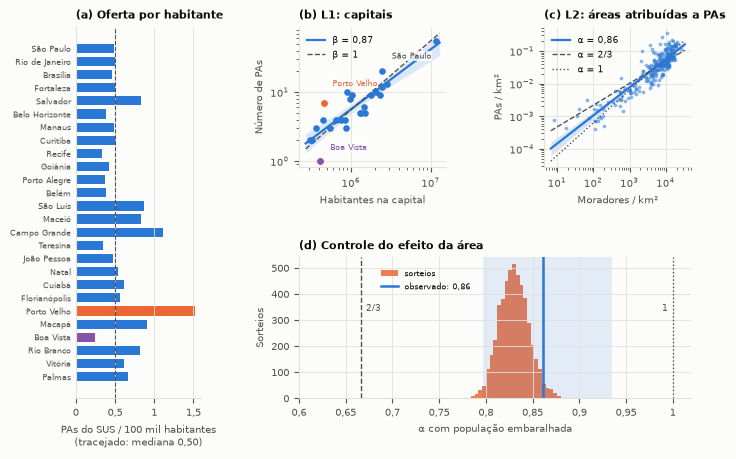

In [4]:
def banda(boot, xs):
    col = next(c for c in boot.columns if c != "c")
    ys = boot[col].to_numpy()[:, None] * xs[None, :] + boot["c"].to_numpy()[:, None]
    return np.percentile(ys, [2.5, 97.5], axis=0)

plt.rcParams.update({"font.size": 7.5, "axes.titlesize": 8})
v = "SUS"
fig = plt.figure(figsize=(8.1, 4.7))
gs = fig.add_gridspec(2, 3, width_ratios=[.85, 1, 1], left=.21, right=.97,
                      bottom=.14, top=.93, hspace=.64, wspace=.70)
axs = [fig.add_subplot(gs[0, 1]), fig.add_subplot(gs[0, 2]), fig.add_subplot(gs[1, 1:3])]

# Mesmo código de cores nos painéis (a) e (b); (c) mostra áreas, não capitais.
destaques = {"Porto Velho": estilo.LARANJA, "Boa Vista": "#8854a8"}  # maior e menor oferta por habitante
from matplotlib.ticker import FuncFormatter
fmt_vir = FuncFormatter(lambda v, _: f"{v:g}".replace(".", ","))
def capital_curta(nome):
    return nome.split(" - ")[0]

# (a) Oferta por habitante: extremos em relação à mediana (não ao ajuste L1).
axb = fig.add_subplot(gs[:, 0])
c1b = cap[v].copy()
c1b["por100k"] = 1e5 * c1b.n_unidades / c1b.populacao_2022
c1b = c1b.sort_values("populacao_2022")
nomes_a = c1b.municipio.map(capital_curta)
cores_a = nomes_a.map(destaques).fillna(estilo.AZUL)
axb.barh(nomes_a, c1b.por100k, color=cores_a, height=.7)
axb.axvline(c1b.por100k.median(), color=estilo.TEXTO_2, ls="--", lw=.8)
axb.tick_params(axis="y", labelsize=5.8, length=0)
axb.grid(axis="y", visible=False); axb.xaxis.set_major_formatter(fmt_vir)
axb.set(xlabel=f"PAs do SUS / 100 mil habitantes\n(tracejado: mediana {c1b.por100k.median():.2f})".replace(".", ","))
axb.set_title("(a) Oferta por habitante", loc="left", fontsize=8, fontweight="bold")

# (b) L1: pontos = capitais; nomes apenas onde cabem sem esconder a nuvem.
ax = axs[0]
c1 = cap[v].copy()
c1["nome"] = c1.municipio.map(capital_curta)
x = np.log10(c1.populacao_2022); y = np.log10(c1.n_unidades)
xs = np.linspace(x.min() - .05, x.max() + .05, 100)
b, c = res1.loc[v, "beta"], res1.loc[v, "c"]
lo, hi = banda(boot1[v], xs)
ax.fill_between(10**xs, 10**lo, 10**hi, color=estilo.AZUL, alpha=.15, lw=0)
ax.scatter(10**x, 10**y, s=14, color=estilo.AZUL, zorder=3)
ax.plot(10**xs, 10**(c + b*xs), color=estilo.AZUL, lw=1.6, label=f"β = {b:.2f}".replace(".", ","))
y0 = y.mean() + (xs - x.mean())
ax.plot(10**xs, 10**y0, "--", color=estilo.TEXTO_2, lw=1, label="β = 1")
for nome, cor in destaques.items():
    r = c1[c1.nome == nome].iloc[0]
    ax.scatter(r.populacao_2022, r.n_unidades, s=30, color=cor,
               edgecolor="white", linewidth=.5, zorder=5)
for nome, desloc, alinhamento in [("Porto Velho", (6, 12), "left"),
                                   ("Boa Vista", (7, 8), "left"),
                                   ("São Paulo", (-3, -13), "right")]:
    r = c1[c1.nome == nome].iloc[0]
    ax.annotate(nome, (r.populacao_2022, r.n_unidades), xytext=desloc,
                textcoords="offset points", ha=alinhamento, fontsize=6,
                color=destaques.get(nome, estilo.TEXTO_2),
                bbox={"facecolor": "white", "edgecolor": "none", "alpha": .85, "pad": .2})
ax.set(xscale="log", yscale="log", xlabel="Habitantes na capital",
       ylabel="Número de PAs", title="(b) L1: capitais")
ax.legend(loc="upper left", fontsize=6.5)

# (c) L2: cada ponto é uma área atribuída a um PA; NÃO é distância ao PA.
ax = axs[1]
a = are[v]; x = a.log10_rho; y = a.log10_D
xs = np.linspace(x.min() - .1, x.max() + .1, 100)
al, c = res2.loc[v, "alpha"], res2.loc[v, "c"]
lo, hi = banda(boot2[v], xs)
ax.fill_between(10**xs, 10**lo, 10**hi, color=estilo.AZUL, alpha=.18, lw=0)
ax.scatter(10**x, 10**y, s=7, color=estilo.AZUL, alpha=.55, lw=0, zorder=3)
ax.plot(10**xs, 10**(c + al*xs), color=estilo.AZUL, lw=1.6, label=f"α = {al:.2f}".replace(".", ","))
for e, ls, nome in [(2/3, "--", "α = 2/3"), (1, ":", "α = 1")]:
    ax.plot(10**xs, 10**(y.mean() + e*(xs - x.mean())), ls,
            color=estilo.TEXTO_2, lw=1, label=nome)
ax.set(xscale="log", yscale="log", xlabel="Moradores / km²",
       ylabel="PAs / km²", title="(c) L2: áreas atribuídas a PAs")
ax.legend(loc="upper left", fontsize=6.5)

# (d) Embaralhamento: controle do denominador comum às duas densidades em (c).
ax = axs[2]
s = nulos[(v, "conjunto")]
ax.hist(s, bins=np.arange(.76, .92, .004), color=estilo.LARANJA,
        alpha=.85, lw=0, label="sorteios")
obs = res2.loc[v, "alpha"]
ax.axvline(obs, color=estilo.AZUL, lw=1.8,
           label=f"observado: {obs:.2f}".replace(".", ","))
ax.axvspan(res2.loc[v, "ic95_inferior"], res2.loc[v, "ic95_superior"],
           color=estilo.AZUL, alpha=.12, lw=0)
ax.axvline(2/3, color=estilo.TEXTO_2, ls="--", lw=1)
ax.axvline(1, color=estilo.TEXTO_2, ls=":", lw=1)
ax.text(2/3 + .005, .62, "2/3", transform=ax.get_xaxis_transform(),
        fontsize=6.5, color=estilo.TEXTO_2)
ax.text(.995, .62, "1", transform=ax.get_xaxis_transform(),
        fontsize=6.5, color=estilo.TEXTO_2, ha="right")
ax.xaxis.set_major_formatter(fmt_vir)
ax.set(xlim=(.6, 1.02), xlabel="α com população embaralhada",
       ylabel="Sorteios", title="(d) Controle do efeito da área")
ax.legend(loc="upper left", bbox_to_anchor=(.19, .97), fontsize=6)
fig.savefig(FIG/"escala_L1_L2.pdf")
fig.savefig(FIG/"escala_L1_L2.png", dpi=220)
plt.show()
plt.rcParams.update({"font.size": 9.5, "axes.titlesize": 11})

In [5]:
t = teste.set_index(["versao", "embaralhamento"])
r = t.loc[("SUS", "conjunto")]; r2 = t.loc[("SUS", "dentro da capital")]
display(Markdown(f"""
**Leitura (SUS).** O α observado é {r.alpha_observado:.3f}. Com a população embaralhada entre todas as áreas, o α fica em média {r.alpha_nulo_media:.3f}
(95% dos sorteios entre {r.alpha_nulo_p2_5:.3f} e {r.alpha_nulo_p97_5:.3f}); embaralhando só dentro de cada capital, em média {r2.alpha_nulo_media:.3f}
(entre {r2.alpha_nulo_p2_5:.3f} e {r2.alpha_nulo_p97_5:.3f}). O valor observado fica acima desses sorteios, mas bem perto deles: a maior parte do expoente
vem da conta ($D$ e $\\rho$ dividem a área), e só uma parte pequena depende da posição real dos PAs. Por isso o α não deve ser lido, sozinho, como prova de que os
PAs estão bem ou mal localizados.
"""))


**Leitura (SUS).** O α observado é 0.861. Com a população embaralhada entre todas as áreas, o α fica em média 0.830
(95% dos sorteios entre 0.801 e 0.862); embaralhando só dentro de cada capital, em média 0.812
(entre 0.797 e 0.828). O valor observado fica acima desses sorteios, mas bem perto deles: a maior parte do expoente
vem da conta ($D$ e $\rho$ dividem a área), e só uma parte pequena depende da posição real dos PAs. Por isso o α não deve ser lido, sozinho, como prova de que os
PAs estão bem ou mal localizados.
